In [1]:
from typing import TypedDict
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

In [2]:
load_dotenv()

True

In [3]:
llm = ChatGroq(
    model="openai/gpt-oss-20b", 
    api_key=os.environ["GROQ_API_KEY"]
)

In [4]:
llm.invoke("hi")

AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond to "hi". It\'s a greeting. We should greet back. Probably keep it friendly.'}, response_metadata={'token_usage': {'completion_tokens': 43, 'prompt_tokens': 72, 'total_tokens': 115, 'completion_time': 0.043952779, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.030010263, 'prompt_tokens_details': None, 'queue_time': 0.376996592, 'total_time': 0.073963042}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8b41efc9a3', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1f65f-334c-7f30-a9a6-fea72244c593-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 43, 'total_tokens': 115, 'output_token_details': {'reasoning': 23}})

In [30]:
class Assignment_State(TypedDict):
    assignment_text:str
    assignment_topic:str
    Summary:str
    Evaluation:str
    Feedback:str

In [31]:
def summary(state:Assignment_State):
    response = llm.invoke(f"Based on the topic {state['assignment_topic']} provide the summary of assignment text {state['assignment_text']}")
    return {"Summary":response.content,"assignment_topic":state['assignment_topic']}


def evaluation(state:Assignment_State):
    response = llm.invoke(f"Based on the summary {state['Summary']} provide evaluation on this topic {state['assignment_topic']}")
    return {"Evaluation":response.content}

def feedback(state:Assignment_State):
    response =llm.invoke(f"based on the summary {state['Summary']}, evaluation {state['Evaluation']} and topic {state['assignment_topic']} please provide feedback to student")
    return {"Feedback":response.content}

In [32]:
d = {
    "assignment_topic":"Artificial Intelligence",
    "assignment_text":"Artificial intelligence (AI) is a branch of computer science that aims to create machines that can perform tasks that typically require human intelligence. These tasks include learning, reasoning, problem-solving, perception, and language understanding. AI systems can be classified into two main categories: narrow AI, which is designed for specific tasks, and general AI, which has the potential to perform any intellectual task that a human can do. The development of AI has led to advancements in various fields such as healthcare, finance, transportation, and entertainment. However, it also raises ethical concerns regarding privacy, job displacement, and decision-making transparency."
}

In [34]:
assignment_summary = summary(d)

In [35]:
summary(d)

{'Summary': '**Summary**\n\nArtificial Intelligence (AI) is a computer science discipline focused on building machines capable of performing tasks that normally require human intelligence—such as learning, reasoning, problem‑solving, perception, and language understanding. AI is generally divided into **narrow AI**, which excels at specific tasks, and **general AI**, which could theoretically handle any intellectual task a human can. While AI has spurred significant progress in domains like healthcare, finance, transportation, and entertainment, it also presents ethical challenges, including concerns over privacy, job displacement, and the transparency of automated decision‑making.',
 'assignment_topic': 'Artificial Intelligence'}

In [37]:
res_eva=evaluation(assignment_summary)

In [42]:
d1={
    "assignment_topic":d['assignment_topic'],
    "Summary":assignment_summary['Summary'],
    "Evaluation":res_eva['Evaluation']
}

In [43]:
feedback(d1)

{'Feedback': '**Feedback on Your AI Overview & Evaluation**\n\nOverall, you’ve crafted a clear, concise snapshot of Artificial Intelligence that balances technical detail with real‑world impact. Below is a quick‑look assessment that highlights what worked well, where you can deepen the analysis, and actionable steps to elevate the piece further.\n\n| What You Did Well | Why It Matters |\n|-------------------|----------------|\n| • **Comprehensive Scope** – Covered learning, reasoning, perception, language, and the narrow/AGI divide. | Sets a solid foundation for any AI discussion. |\n| • **Balanced Tone** – Acknowledged both opportunities and risks. | Shows maturity in understanding AI’s dual nature. |\n| • **Accessible Language** – Jargon‑free yet accurate. | Makes the content approachable for non‑experts. |\n| • **Logical Flow** – “What, How, Why, Impact” structure. | Readers can follow the narrative easily. |\n\n| Areas for Improvement | Why It Matters |\n|-----------------------|--

In [44]:
from langgraph.graph import StateGraph, START, END

In [45]:
workflow = StateGraph(Assignment_State)
workflow.add_node("assignment_summary",summary)
workflow.add_node("evaluation",evaluation)
workflow.add_node("feedback",feedback)

In [46]:
workflow.add_edge(START,"assignment_summary")
workflow.add_edge("assignment_summary","evaluation")    
workflow.add_edge("evaluation","feedback")
workflow.add_edge("feedback",END)

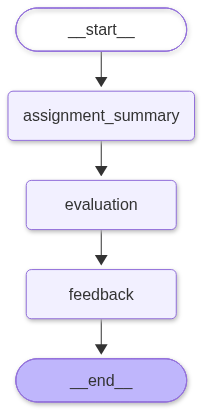

In [47]:
workflow.compile()

In [49]:
linear=workflow.compile()

In [50]:
linear.invoke(d)

{'assignment_text': 'Artificial intelligence (AI) is a branch of computer science that aims to create machines that can perform tasks that typically require human intelligence. These tasks include learning, reasoning, problem-solving, perception, and language understanding. AI systems can be classified into two main categories: narrow AI, which is designed for specific tasks, and general AI, which has the potential to perform any intellectual task that a human can do. The development of AI has led to advancements in various fields such as healthcare, finance, transportation, and entertainment. However, it also raises ethical concerns regarding privacy, job displacement, and decision-making transparency.',
 'assignment_topic': 'Artificial Intelligence',
 'Summary': '**Summary of the Assignment Text on Artificial Intelligence**\n\n- **Definition & Goals**: AI is a computer‑science field that builds machines capable of performing tasks normally requiring human intelligence—learning, reaso